## Thanks to the SCIMBA team (E. Franck, V. Michel-Dansac, ...)  https://www.scimba.org
----------------------------------------------------------------
# A combined PINNs-DeepRitz

In this tutorial we use a tutorial for  a simple combined PINNs-DeepRitz in the disk.
After running the tuto, the exercize is to implement a differnet BC, homogeneous Dirchlet on the upper part
and non homogeneous Neumann on the lower part, still preserving the same solution
    

## Problem
We desire to solve the Poisson problem in the disk $\mathcal D=\{x^2+y^2\leq 1\}$
$$
-\mu \Delta u(x,y) = f (x,y)
$$
with homogogenous Dirichlet boundary conditions (bcs)
$$
u(x,y)=0 \mbox{ for }(x,y)\in \partial \mathcal D=\{x^2+y^2=1 \}.
$$
We will also consider homogogenous Dirichlet boundary conditions (bcs)
$u(x,y)=0$ on the upper part of $ \partial \mathcal D$, complemented with 
non homogenous boundary conditions on the lower part of the boundary
$$
\partial _n u(x,y)= \left( \nabla u \cdot n \right) (x,y)=g, \quad
(x,y)\in \mathcal D \mbox{ and } y<0.
$$

## Loss
Our goal is to minimize Loss functions like
$$
J=\int_{\mathcal D} \left( \frac \mu 2 \left| \nabla u (x,y) \right|^2  - f(x,y) u(x,y) \right) dxdy
+\lambda \int_{\partial \mathcal D } |u(x,y)|^2 d\sigma.
$$
The first step is to run and analyze the following script.

## 2D laplacian on a disk
Solves a 2D Poisson PDE with Dirichlet BCs using the Deep Ritz method and PINNs.

$$\left\{\begin{array}{rl}-\mu \Delta u & = f \text{ in } \Omega \times M \\
    u & = g \text{ on } \partial \Omega \times M\end{array}\right.$$

where $x = (x_1, x_2) \in \Omega = \mathcal{D}$ (with $\mathcal{D}$ being the disk with center $(x_1^0, x_2^0) = (-0.5, 0.5)$), $f$ such that $u(x_1, x_2, \mu) = 0.25 \mu (1 - (x_1 - x_1^0)^2 - (x_2 - x_2^0)^2)$, $g = 0$ and $\mu \in M = [0.5, 1]$. 


In [1]:
import matplotlib.pyplot as plt
import torch

from scimba_torch.approximation_space.nn_space import NNxSpace
from scimba_torch.domain.meshless_domain.domain_2d import Disk2D
from scimba_torch.integration.monte_carlo import DomainSampler, TensorizedSampler
from scimba_torch.integration.monte_carlo_parameters import UniformParametricSampler
from scimba_torch.neural_nets.coordinates_based_nets.mlp import GenericMLP
from scimba_torch.numerical_solvers.elliptic_pde.deep_ritz import (
    DeepRitzElliptic,
    NaturalGradientDeepRitzElliptic,
)
from scimba_torch.numerical_solvers.elliptic_pde.pinns import (
    NaturalGradientPinnsElliptic,
)
from scimba_torch.physical_models.elliptic_pde.laplacians import (
    Laplacian2DDirichletRitzForm,
    Laplacian2DDirichletStrongForm,
)
from scimba_torch.plots.plots_nd import plot_abstract_approx_spaces
from scimba_torch.utils.scimba_tensors import LabelTensor



def exact_sol(x: LabelTensor, mu: LabelTensor):
    x1, x2 = x.get_components()
    mu1 = mu.get_components()
    return 0.25 * mu1 * (1 - (x1 - center[0]) ** 2 - (x2 - center[1]) ** 2)


def f_rhs(x: LabelTensor, mu: LabelTensor):
    # x1, x2 = x.get_components()
    mu1 = mu.get_components()
    return mu1**2


def f_bc(x: LabelTensor, mu: LabelTensor):
    x1, _ = x.get_components()
    # mu1 = mu.get_components()
    return torch.zeros_like(x1)

center = (-0., 0.)
domain_x = Disk2D(center, 1, is_main_domain=True)
domain_mu = [[1.0, 1.0]]
# domain_mu = [[0.5, 1.0]]
sampler = TensorizedSampler(
    [DomainSampler(domain_x), UniformParametricSampler(domain_mu)]
)


def post_processing(inputs: torch.Tensor, x: LabelTensor, mu: LabelTensor):
    x1, x2 = x.get_components()
    # mu1 = mu.get_components()
    phi = (x1 - center[0]) ** 2 + (x2 - center[1]) ** 2 - 1.0
    return inputs * phi


def functional_post_processing(
    func, x: torch.Tensor, mu: torch.Tensor, theta: torch.Tensor
) -> torch.Tensor:
    phi = (x[0] - center[0]) ** 2 + (x[1] - center[1]) ** 2 - 1.0
    return func(x, mu, theta) * phi

In [2]:
space2 = NNxSpace(1, 1, GenericMLP, domain_x, sampler, layer_sizes=[64],
    post_processing=post_processing)

pde2 = Laplacian2DDirichletRitzForm(space2, f=f_rhs, g=f_bc)

ritz = DeepRitzElliptic( pde2, bc_type="strong", )

ritz.solve(epochs=2000, n_collocation=40000, n_bc_collocation=1000, verbose=False)

Training: 100%|||||||||||||| 2000/2000[01:35<00:00] , loss: -4.3e-03 -> -6.5e-02


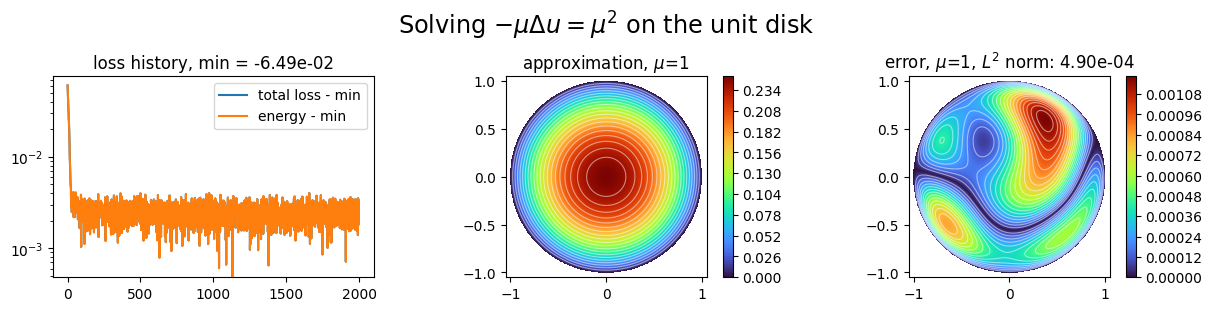

In [4]:
plot_abstract_approx_spaces(
    (ritz.space),
    domain_x, domain_mu,
    loss=(ritz.losses),
    error=exact_sol,
    draw_contours=True,
    n_drawn_contours=20,
    parameters_values="mean",
    title=r"Solving $-\mu\Delta u = \mu^2$ on the unit disk",
    titles=(
        "RITZ with no preconditioning",
    ),
)
plt.show()

## Pure Deep Ritz method
Modify the class below so as to solve
the Laplace problem in the disk $\mathcal D=\{x^2+y^2\leq 1\}$
$$
-\mu \Delta u(x,y) + u(x,y) = f (x,y)
$$
equipped with  homogogenous Dirichlet boundary conditions (bcs)
$u(x,y)=0$ on the upper part of $ \partial \mathcal D$, 

complemented with 
non homogenous boundary conditions on the lower part of the boundary
$$
\partial _n u(x,y)= \left( \nabla u \cdot n \right) (x,y)=g, \quad
(x,y)\in \mathcal D \mbox{ and } y<0.
$$

In [5]:
class Laplacian2DDirichletRitzForm(RitzFormEllipticPDE):
    """Implementation of a 2D Laplacian problem with Dirichlet BCs in Ritz form.

    Args:
        space: The approximation space for the problem.
        f: Callable, represents the source term f(x, μ) (default: f=1).
        g: Callable, represents the Dirichlet boundary condition g(x, μ) (default: g=0).
        **kwargs: Additional keyword arguments.
    """

    def __init__(
        self,
        space: AbstractApproxSpace,
        f: Callable = ones,
        g: Callable = zeros,
        **kwargs,
    ):
        super().__init__(space, bc_residual_size=1, **kwargs)
        self.f = f
        self.g = g


[docs]
    def linearform(
        self, w: MultiLabelTensor, x: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        """Compute the linear form of the PDE.

        Args:
            w: State tensor.
            x: Spatial coordinates tensor.
            mu: Parameter tensor.

        Returns:
            The linear form result.
        """
        u = w.get_components()
        return self.f(x, mu) * u




[docs]
    def quadraticform(
        self, w: MultiLabelTensor, x: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        """Compute the quadratic form of the PDE.

        Args:
            w: State tensor.
            x: Spatial coordinates tensor.
            mu: Parameter tensor.

        Returns:
            The quadratic form result.
        """
        u = w.get_components()
        alpha = mu.get_components()
        u_x, u_y = self.grad(u, x)
        return 0.5 * alpha * (u_x**2.0 + u_y**2.0)




[docs]
    def energy_matrix(
        self, vals: dict, x: torch.Tensor, mu: torch.Tensor
    ) -> torch.Tensor:
        """Compute the energy matrix for the Ritz formulation.

        Args:
            vals: Dictionary containing precomputed values.
            x: Spatial coordinates tensor.
            mu: Parameter tensor.

        Returns:
            The energy matrix.
        """
        N = x.shape[0]
        Phi = (vals["eval_and_gradx_and_gradtheta"]).squeeze()
        Phi2 = Phi * mu.view(-1, 1, 1)
        return torch.einsum("ijl,ikl->jk", Phi2, Phi) / N



    # def functional_bilinearform(
    #     self,
    #     u: VarArgCallable,
    #     v: VarArgCallable,
    #     x: torch.Tensor,
    #     mu: torch.Tensor,
    #     theta: torch.Tensor,
    # ) -> torch.Tensor:
    #     grad_u_x_mu_theta = torch.func.grad(u, 0)(x, mu, theta)
    #     grad_v_x_mu_theta = torch.func.grad(v, 0)(x, mu, theta)
    #     return (
    #         mu[0]
    #         * (
    #             grad_u_x_mu_theta[0] * grad_v_x_mu_theta[0]
    #             + grad_u_x_mu_theta[1] * grad_v_x_mu_theta[1]
    #         )[None]
    #     )


[docs]
    def bc_rhs(
        self, w: MultiLabelTensor, x: LabelTensor, n: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        """Compute the RHS for the boundary conditions.

        Args:
            w: State tensor.
            x: Boundary coordinates tensor.
            n: Normal vector tensor.
            mu: Parameter tensor.

        Returns:
            The boundary condition g(x, μ).
        """
        return self.g(x, mu)



    # Dirichlet condition

[docs]
    def bc_operator(
        self, w: MultiLabelTensor, x: LabelTensor, n: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        """Compute the operator for the boundary conditions.

        Args:
            w: State tensor.
            x: Boundary coordinates tensor.
            n: Normal vector tensor.
            mu: Parameter tensor.

        Returns:
            The boundary operator applied to the state.
        """
        u = w.get_components()
        return u




[docs]
    def functional_operator_bc(
        self,
        func: VarArgCallable,
        x: torch.Tensor,
        n: torch.Tensor,
        mu: torch.Tensor,
        theta: torch.Tensor,
    ) -> torch.Tensor:
        """Apply the functional operator for boundary conditions.

        Args:
            func: The callable function to apply.
            x: Spatial coordinates tensor.
            n: Normal vector tensor.
            mu: Parameter tensor.
            theta: Theta parameter tensor.

        Returns:
            The result of applying the functional operator.
        """
        return func(x, mu, theta)



IndentationError: unexpected indent (3227703964.py, line 24)